In [1]:
%load_ext autoreload
%autoreload 2

# Résultats — CNN 2D anti-spoofing

Analyse du modèle entraîné (`checkpoints/cnn2d/model.pt`), 14 epochs,
early stopping (patience=5), meilleur EER validation = 0.0011.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent  # notebooks/ -> racine du projet
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

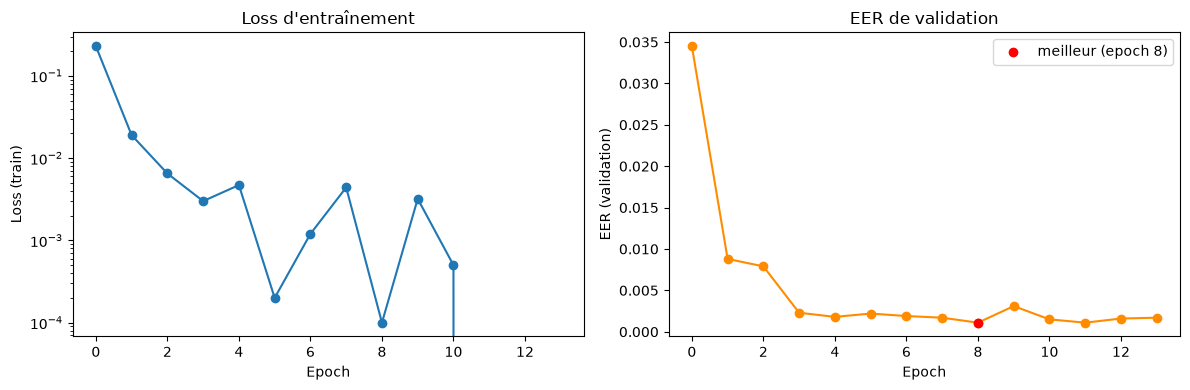

In [3]:
history = pd.read_csv(PROJECT_ROOT / "results" / "history_cnn2d.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (train)")
axes[0].set_title("Loss d'entraînement")
axes[0].set_yscale("log")  # la loss descend de 0.23 à 0.0000x : l'échelle log évite d'écraser les dernières epochs

axes[1].plot(history["epoch"], history["val_eer"], marker="o", color="darkorange")
best_epoch = history["val_eer"].idxmin()
axes[1].scatter(history.loc[best_epoch, "epoch"], history.loc[best_epoch, "val_eer"],
                 color="red", zorder=5, label=f"meilleur (epoch {int(history.loc[best_epoch, 'epoch'])})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("EER (validation)")
axes[1].set_title("EER de validation")
axes[1].legend()

plt.tight_layout()
plt.show()

**Note** : la loss d'entraînement des epochs 11 à 13 est exactement 0.0000 (arrondi),
d'où leur absence sur l'échelle logarithmique. Le modèle atteint une perte
numériquement nulle sur le train set dès l'epoch 8, ce qui correspond au moment
où l'EER de validation cesse de s'améliorer — signe que le réseau mémorise les
données d'entraînement plutôt que d'apprendre des traits supplémentaires
généralisables. L'early stopping (patience=5) stoppe l'entraînement à l'epoch 13
avant que ce sur-apprentissage ne dégrade davantage les performances.

## 2. Évaluation sur le split TEST — courbe ROC

In [4]:
import torch
from torch.utils.data import DataLoader

from src.data import load_splits, ASVspoofDataset
from src.models import build_model
from src.train import collect_predictions, DEVICE
from src.metrics import compute_eer

print(f"Device : {DEVICE}")

model = build_model("cnn2d")
checkpoint_path = PROJECT_ROOT / "checkpoints" / "cnn2d" / "model.pt"
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
print(f"Modèle chargé depuis {checkpoint_path}")

splits = load_splits()
test_loader = DataLoader(
    ASVspoofDataset(splits["test"], duration_s=4.0),
    batch_size=32, shuffle=False, num_workers=4,
)

labels, scores, system_ids = collect_predictions(model, test_loader, desc="test")
labels_np = labels.numpy()
scores_np = scores.numpy()

eer, threshold = compute_eer(labels_np, scores_np)
print(f"\nEER global sur TEST : {eer:.4f} (seuil : {threshold:.4f})")

/home/docker/speech-deepfake-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda
Modèle chargé depuis /home/docker/speech-deepfake-detection/checkpoints/cnn2d/model.pt


Using the latest cached version of the dataset since Bisher/ASVspoof_2019_LA couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'default' at /home/docker/speech-deepfake-detection/data/huggingface_cache/Bisher___as_vspoof_2019_la/default/0.0.0/aea92dd83a9c56e070c0b1e9f02e7c0d96216a4c (last modified on Tue Nov 17 16:27:59 2026).
                                                         


EER global sur TEST : 0.1876 (seuil : 0.0000)


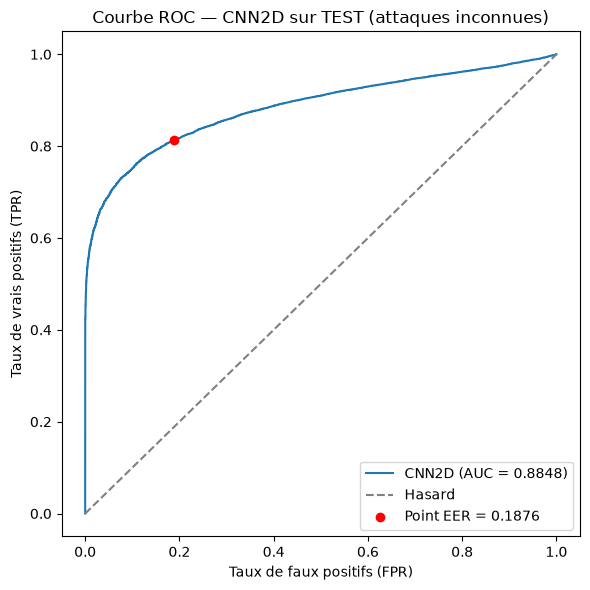

In [5]:
from sklearn.metrics import roc_curve, auc
import numpy as np

fpr, tpr, thresholds = roc_curve(labels_np, scores_np, pos_label=1)
roc_auc = auc(fpr, tpr)

fnr = 1 - tpr
idx_eer = np.nanargmin(np.abs(fpr - fnr))

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"CNN2D (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Hasard")
plt.scatter(fpr[idx_eer], tpr[idx_eer], color="red", zorder=5,
            label=f"Point EER = {eer:.4f}")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC — CNN2D sur TEST (attaques inconnues)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. EER par type d'attaque

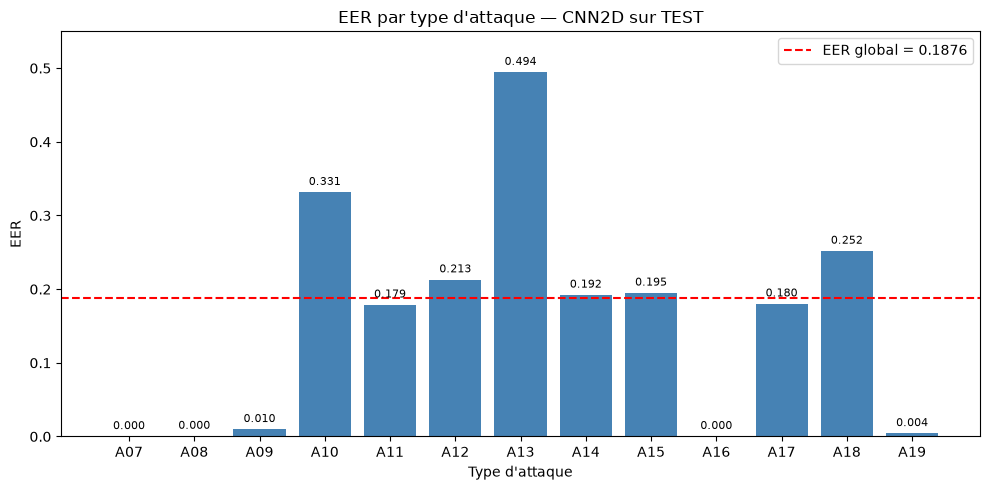

In [6]:
from src.metrics import per_attack_eer

per_attack = per_attack_eer(labels_np, scores_np, system_ids)

attack_ids = list(per_attack.keys())
eer_values = list(per_attack.values())

plt.figure(figsize=(10, 5))
bars = plt.bar(attack_ids, eer_values, color="steelblue")

# Seuil de référence : l'EER global, pour voir d'un coup d'œil quelles attaques
# sont plus difficiles ou plus faciles que la moyenne
plt.axhline(eer, color="red", linestyle="--", label=f"EER global = {eer:.4f}")

for bar, value in zip(bars, eer_values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}",
              ha="center", fontsize=8)

plt.xlabel("Type d'attaque")
plt.ylabel("EER")
plt.title("EER par type d'attaque — CNN2D sur TEST")
plt.ylim(0, 0.55)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Interprétation

**Détection quasi parfaite (EER < 1%) : A07, A08, A09, A16, A19**
A16 et A19 réutilisent les mêmes algorithmes que deux attaques du jeu
d'entraînement (A04 et A06 respectivement), entraînés simplement sur des
données différentes — le modèle a donc littéralement déjà vu ces artefacts
pendant l'entraînement. A07, A08 et A09 utilisent des vocodeurs neuronaux
(WORLD+GAN, filtre de source neuronal, Vocaine) dont les artefacts spectraux
sont apparemment assez proches de ceux déjà appris pour généraliser facilement.

**Difficulté marquée : A10 (EER = 0.331) et A13 (EER = 0.494, quasi aléatoire)**
A13 utilise un simple réseau feed-forward suivi d'un filtrage spectral —
une méthode de synthèse structurellement très différente de tout ce que le
modèle a vu à l'entraînement, ce qui explique l'échec quasi total. A10
(Tacotron2 + WaveRNN, bout en bout) est connu dans la littérature ASVspoof
comme une attaque systématiquement difficile à détecter, across de nombreux
systèmes soumis au challenge — notre résultat est cohérent avec ce constat
documenté, pas une faiblesse spécifique à cette architecture.

**Conclusion générale**
Le CNN généralise très bien aux attaques partageant une famille algorithmique
ou des artefacts spectraux proches des données d'entraînement (A01-A06), mais
peine sur les attaques structurellement différentes. L'EER global de 0.1876
sur TEST masque cette hétérogénéité : la performance du modèle est bimodale
plutôt qu'uniforme, un point important à souligner dans le rapport plutôt que
de se limiter au chiffre global.

**Limite à mentionner** : ce modèle a été entraîné uniquement sur A01-A06.
Un recouvrement avec des types d'attaques plus variés à l'entraînement (ou
une architecture combinant plusieurs représentations, 2D + 1D) serait une
piste naturelle d'amélioration — à explorer si le groupe construit un second
modèle en comparaison.